# Extended validation of collected scouting models

This notebook analyses genuinely executed real FBref archive diagnostics. It extends notebook 06 with person-block refits, PCA direction/subspace stability, frozen-cluster seasonal changes, position-specific retrieval and the six original playing styles. These are **post-hoc diagnostics on already viewed cohorts**. No new held-out confirmation, transfer-success estimate or forecast is claimed. Existing models and raw data are preserved.

In [1]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd()
while not (ROOT/'src/config.py').exists():
    if ROOT == ROOT.parent: raise RuntimeError('Run inside the repository')
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
from src.data.provenance import sha256
result = json.loads((ROOT/'reports/collected_validation_results.json').read_text())
base = json.loads((ROOT/'reports/collected_model_results.json').read_text())
for path, expected in result['preserved_input_hashes'].items():
    assert sha256(ROOT/path) == expected, path
for info in result['experiments'].values():
    for path, expected in info['output_files'].items(): assert sha256(ROOT/path) == expected, path
def frame(name, suffix):
    return pd.read_csv(ROOT/f'reports/experiments/collected_validation_{name}_{suffix}.csv')
def figure(name, suffix):
    display(Image(filename=str(ROOT/f'reports/experiments/collected_validation_{name}_{suffix}.png')))
display(Markdown('All source, baseline-model and diagnostic artifact hashes verified. Validation version: `'+result['validation_version']+'`.'))


All source, baseline-model and diagnostic artifact hashes verified. Validation version: `eeccdb33fbcfbedaa60a4c9398d02584cca3f837d461fa765e735f897b9f5b09`.

## Design and experimental unit

Thirty bootstrap draws sample source player identities with replacement. Each draw retains **all development-season observations** of each sampled person; repeated draws act as weights on observed records. Median imputation, standard scaling, PCA and K-means are refitted on those development rows. K and PCA width remain fixed at the previously selected values. No validation/holdout row is fitted. Player-level sampling accounts for repeated seasons within training, while still treating players as independent; club/competition dependencies are not modelled. Out-of-bag (OOB) players were absent from the bootstrap fitting sample. ARI is label-permutation invariant, and evaluates assignment agreement with the original development model, not correctness.

In [2]:
display(pd.DataFrame([dict(cohort=name, development_rows=info['train_rows'], development_people=info['train_people'], seasons=', '.join(info['train_seasons']), method=info['selected_method'], base_run_id=info['base_run_id']) for name,info in result['experiments'].items()]))
display(pd.DataFrame([result['parameters']]))


,cohort,development_rows,development_people,seasons,method,base_run_id
0,offensive,1183,644,"2020-2021, 2021-2022, 2022-2023",euclidean_profile,c9e47c4ca7984652b79dd95131063041
1,core,795,525,"2020-2021, 2021-2022",euclidean_profile,28aca2ec30514eafa181b7945f2c6dcd
2,attack_on_core,795,525,"2020-2021, 2021-2022",euclidean_profile,54262e95cd684023bed779bced078bb2


,person_block_trials,seed,query_bootstrap_trials,k,pca,interpretation
0,30,42,500,fixed_previously_selected,fixed_previously_selected_width,post_hoc_diagnostics_no_parameter_tuning


## K-means: population sensitivity beyond initialization

All refits predict clusters on the same original training reference set, with OOB agreement reported separately. The CSV records OOB sample sizes and explicitly marks insufficient cluster diversity. Centroids are matched by minimum total distance after converting them to the original standardized feature space. Quantiles describe the conditional resampling distribution; they are not population accuracy confidence intervals.

### offensive

,adjusted_rand_reference,adjusted_rand_out_of_bag,matched_centroid_distance_mean,out_of_bag_people
count,30.000000,30.000000,30.000000,30.000000
mean,0.945128,0.942903,0.148159,236.266667
std,0.045117,0.046419,0.074747,6.612075
min,0.812712,0.813259,0.038959,221.000000
5%,0.852797,0.848163,0.058455,222.900000
50%,0.943072,0.957847,0.147810,238.000000
95%,0.994931,0.995948,0.303317,243.550000
max,1.000000,1.000000,0.335755,247.000000


,trials
out_of_bag_status,
measured,30


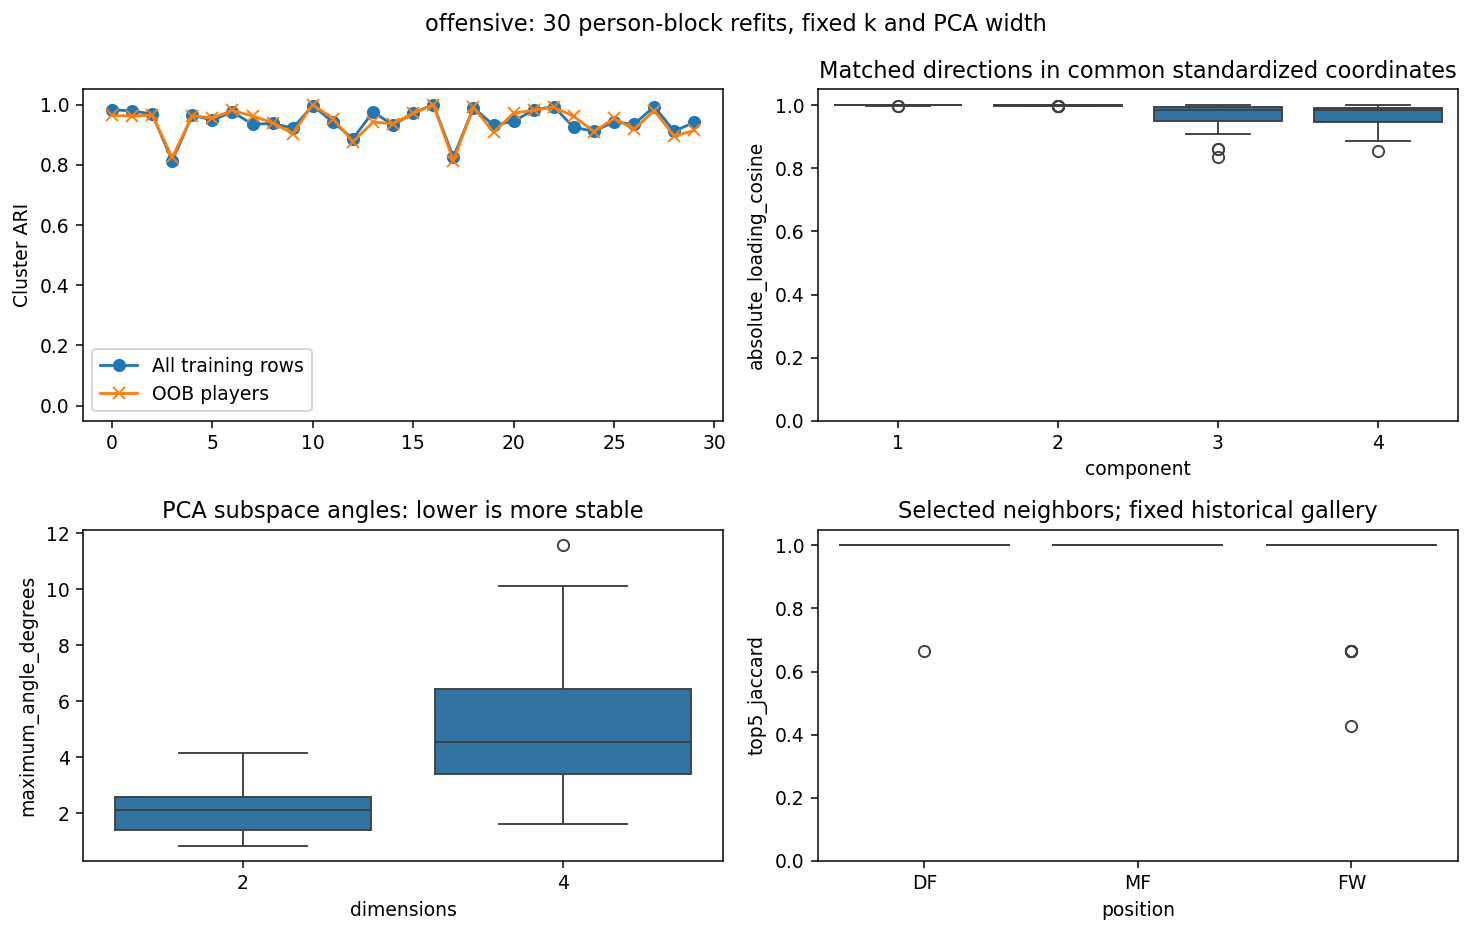

OOB ARI averaged 0.943, with a minimum of 0.813. This measures assignment sensitivity to sampled players; it does not validate tactical labels. The two original clusters remain broad attacking-output groupings.

### core

,adjusted_rand_reference,adjusted_rand_out_of_bag,matched_centroid_distance_mean,out_of_bag_people
count,30.000000,30.000000,30.000000,30.000000
mean,0.970881,0.973136,0.166259,192.300000
std,0.020603,0.023649,0.042141,7.395945
min,0.930081,0.914507,0.108977,177.000000
5%,0.932431,0.928292,0.114453,181.450000
50%,0.974775,0.979304,0.159184,193.000000
95%,0.994933,1.000000,0.241993,203.100000
max,1.000000,1.000000,0.258195,205.000000


,trials
out_of_bag_status,
measured,30


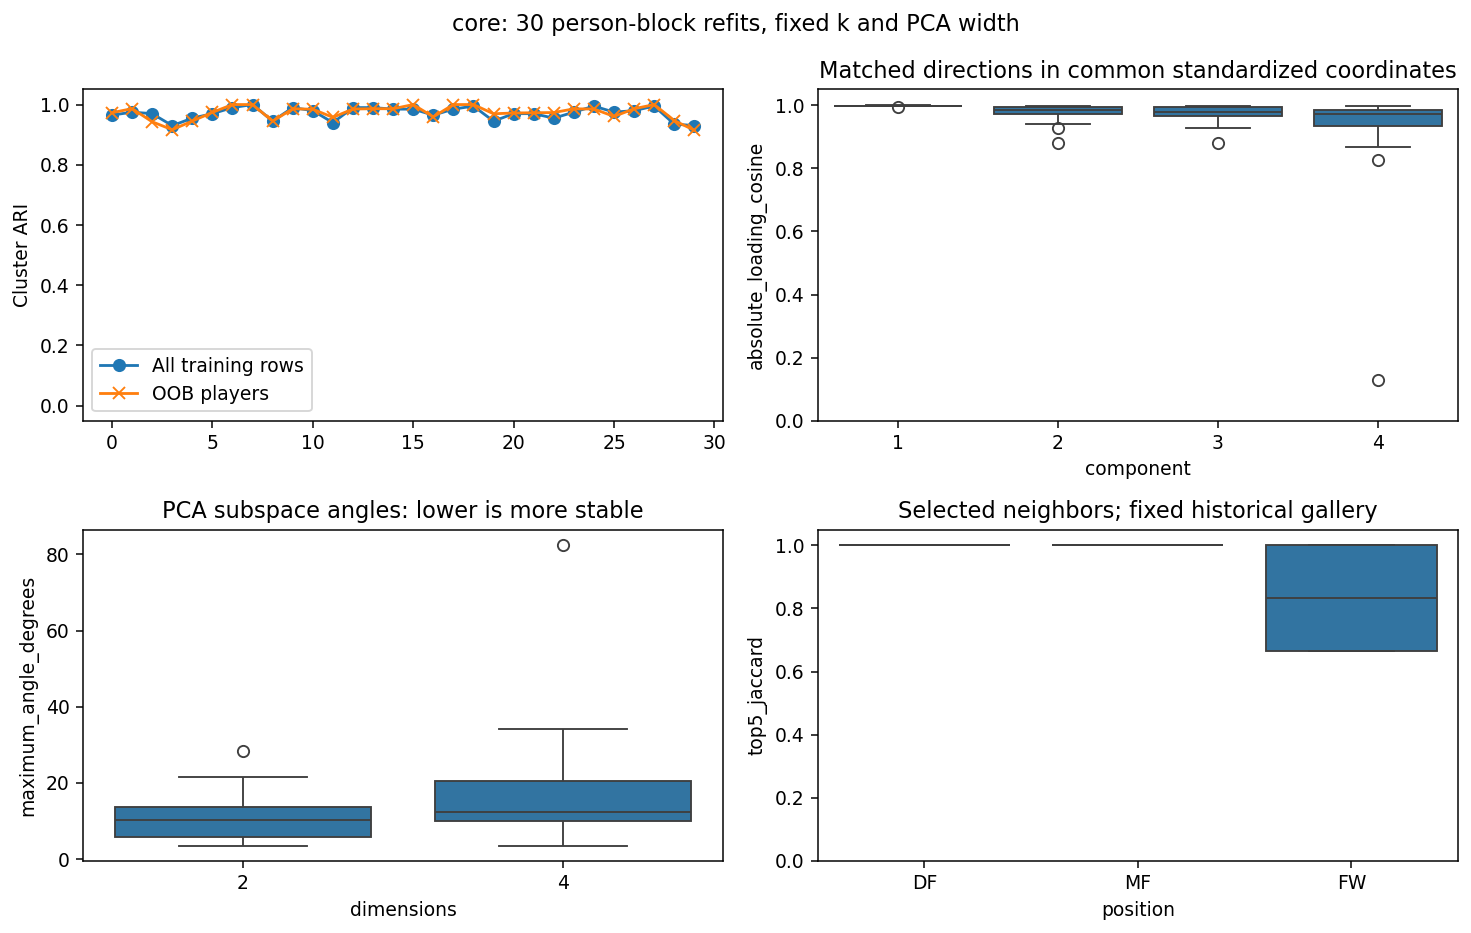

OOB ARI averaged 0.973, with a minimum of 0.915. This measures assignment sensitivity to sampled players; it does not validate tactical labels. The two original clusters remain broad attacking-output groupings.

### attack_on_core

,adjusted_rand_reference,adjusted_rand_out_of_bag,matched_centroid_distance_mean,out_of_bag_people
count,30.000000,30.000000,30.000000,30.000000
mean,0.929826,0.930510,0.164668,192.300000
std,0.063791,0.066488,0.080869,7.395945
min,0.800870,0.783436,0.053995,177.000000
5%,0.825831,0.801867,0.063639,181.450000
50%,0.953918,0.952593,0.132417,193.000000
95%,0.994817,1.000000,0.296920,203.100000
max,0.994820,1.000000,0.359383,205.000000


,trials
out_of_bag_status,
measured,30


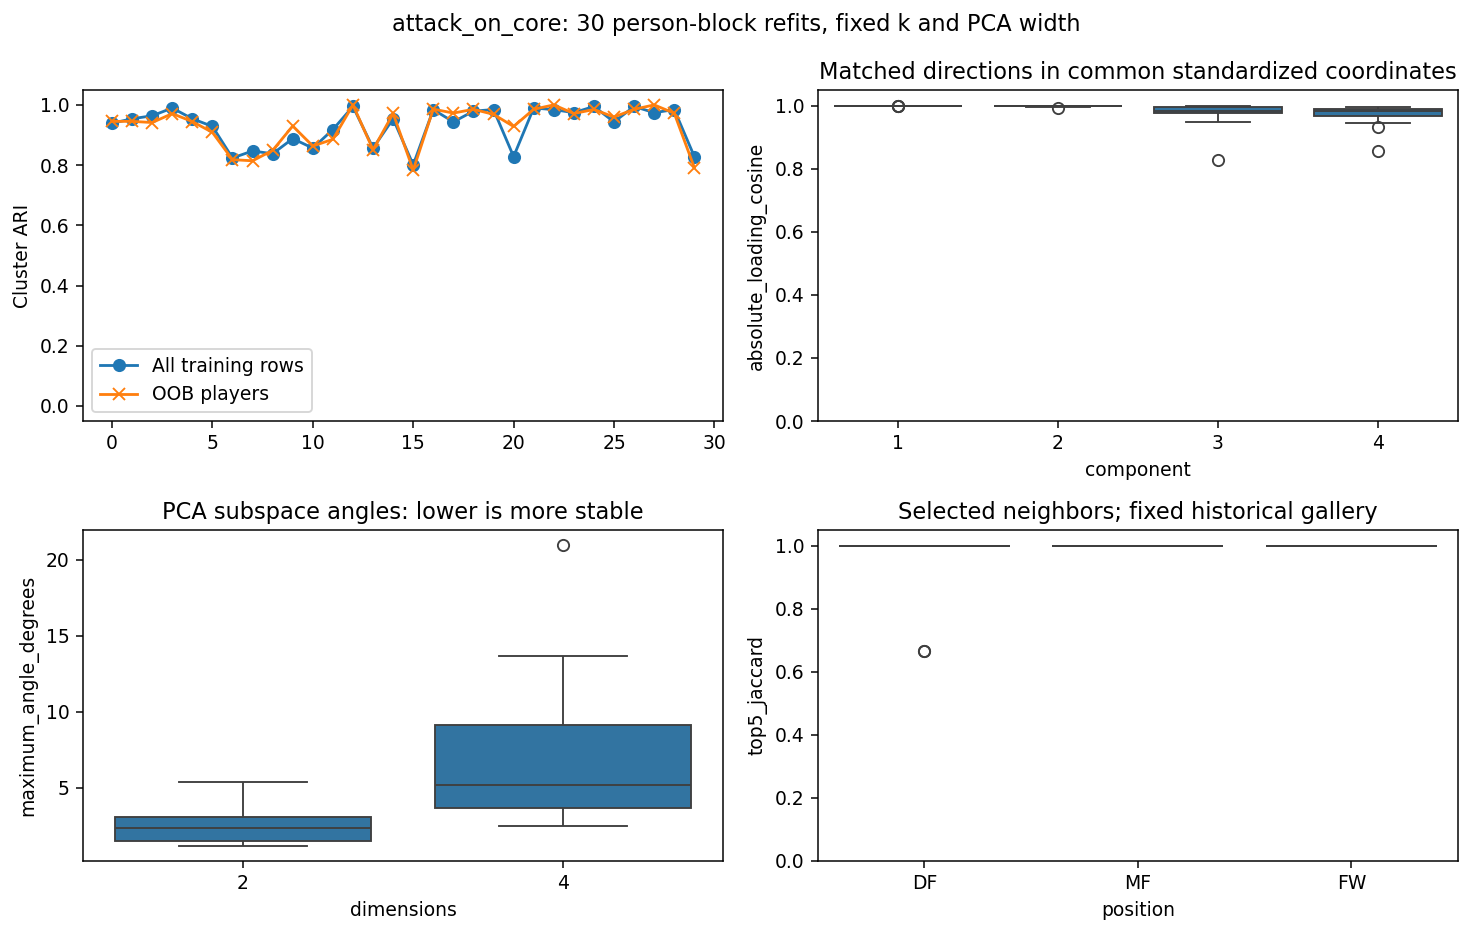

OOB ARI averaged 0.931, with a minimum of 0.783. This measures assignment sensitivity to sampled players; it does not validate tactical labels. The two original clusters remain broad attacking-output groupings.

In [3]:
for name in result['experiments']:
    clusters=frame(name,'cluster_bootstrap')
    display(Markdown('### '+name))
    display(clusters[['adjusted_rand_reference','adjusted_rand_out_of_bag','matched_centroid_distance_mean','out_of_bag_people']].describe(percentiles=[.05,.5,.95]))
    display(clusters.out_of_bag_status.value_counts().to_frame('trials'))
    figure(name,'bootstrap')
    display(Markdown(f"OOB ARI averaged {clusters.adjusted_rand_out_of_bag.mean():.3f}, with a minimum of {clusters.adjusted_rand_out_of_bag.min():.3f}. This measures assignment sensitivity to sampled players; it does not validate tactical labels. The two original clusters remain broad attacking-output groupings."))


## PCA: loadings, subspaces and variance

Component signs and ordering are arbitrary. Bootstrap score directions are converted to the original standardized coordinates using the ratio of original to bootstrap feature scales, normalized and matched by maximum absolute loading cosine. A rotation among close eigenvectors can change individual loadings without changing their joint space, so top-two and top-four principal angles are reported separately (zero means the same subspace). Explained variance belongs to each bootstrap fit's standardized covariance and is not directly a share of a fixed original covariance. These checks complement notebook 06's observed retrieval loss after PCA compression.

In [4]:
for name in result['experiments']:
    display(Markdown('### '+name))
    display(frame(name,'pca_loading_bootstrap').groupby('component').absolute_loading_cosine.agg(['mean','min','max']))
    display(frame(name,'pca_subspace_bootstrap').groupby('dimensions').maximum_angle_degrees.agg(['mean','min','max']))
    display(frame(name,'pca_variance_bootstrap').groupby('component').cumulative_variance.agg(['mean','min','max']))
    angles=frame(name,'pca_subspace_bootstrap')
    display(Markdown(f"The largest top-four principal angle averaged {angles[angles.dimensions.eq(4)].maximum_angle_degrees.mean():.2f}°. Direction stability alone cannot establish that compressed features retain the information needed for recommendations; the temporal retrieval comparison remains the relevant proxy test."))
core_loadings=frame('core','pca_loading_bootstrap')
worst=core_loadings[core_loadings.component.eq(4)].sort_values('absolute_loading_cosine').iloc[0]
eigenvalues=frame('core','pca_eigenvalues')
display(eigenvalues[eigenvalues.trial.isin([-1,int(worst.trial)]) & eigenvalues.component.isin([4,5])])
worst_angle=frame('core','pca_subspace_bootstrap').query('dimensions == 4').set_index('trial').loc[int(worst.trial)].maximum_angle_degrees
display(Markdown(f"Core PC4 is particularly sensitive in trial {int(worst.trial)}: matched loading cosine {worst.absolute_loading_cosine:.3f}, largest four-dimensional angle {worst_angle:.2f}°. The fourth/fifth eigenvalues are relatively close, especially in this resample, consistent with sensitivity at the four-component truncation boundary. This is not only a harmless sign flip or a rotation inside an unchanged retained subspace. Avoid assigning a fixed tactical meaning to PC4."))


### offensive

,mean,min,max
component,,,
1,0.999469,0.998164,0.999950
2,0.999036,0.996681,0.999926
3,0.964052,0.837584,0.999571
4,0.966673,0.853773,0.999587


,mean,min,max
dimensions,,,
2,2.113389,0.837889,4.159849
4,4.977688,1.608895,11.590467


,mean,min,max
component,,,
1,0.660508,0.630305,0.682846
2,0.878296,0.862807,0.890128
3,0.927966,0.922244,0.935103
4,0.967378,0.963389,0.971934


The largest top-four principal angle averaged 4.98°. Direction stability alone cannot establish that compressed features retain the information needed for recommendations; the temporal retrieval comparison remains the relevant proxy test.

...

,mean,min,max
dimensions,,,
2,2.508734,1.175830,5.349918
4,6.809963,2.510134,20.993663


,mean,min,max
component,,,
1,0.666485,0.635329,0.701579
2,0.876876,0.858944,0.892943
3,0.927315,0.915403,0.936635
4,0.964233,0.958263,0.969980


The largest top-four principal angle averaged 6.81°. Direction stability alone cannot establish that compressed features retain the information needed for recommendations; the temporal retrieval comparison remains the relevant proxy test.

,trial,component,eigenvalue,gap_to_next,scope
3,-1,4,0.671818,0.105783,original_development
4,-1,5,0.566034,0.051226,original_development
183,19,4,0.600163,0.039429,bootstrap_development
184,19,5,0.560735,0.051272,bootstrap_development


Core PC4 is particularly sensitive in trial 19: matched loading cosine 0.130, largest four-dimensional angle 82.54°. The fourth/fifth eigenvalues are relatively close, especially in this resample, consistent with sensitivity at the four-component truncation boundary. This is not only a harmless sign flip or a rotation inside an unchanged retained subspace. Avoid assigning a fixed tactical meaning to PC4.

## Independent replay of the first two real bootstrap draws

The following cell refits the core development bootstrap twice with the saved seed and verifies its numeric outputs against the first two recorded trials. It uses observed development data from the frozen model and does not produce new experiment runs.

In [5]:
from src.models.recommend import PlayerRecommender
from src.models.validation import resampling_validation
rec=PlayerRecommender.load(ROOT/result['experiments']['core']['base_model_path'])
replayed=resampling_validation(rec,trials=2,seed=result['parameters']['seed'])
for suffix in ['cluster_bootstrap','pca_loading_bootstrap','pca_subspace_bootstrap','pca_variance_bootstrap','ranking_bootstrap','pca_eigenvalues']:
    expected=frame('core',suffix); expected=expected[expected.trial.lt(2)].reset_index(drop=True)
    actual=replayed[suffix].reset_index(drop=True)
    pd.testing.assert_frame_equal(actual,expected,check_dtype=False,check_exact=False,rtol=1e-9,atol=1e-10)
display(Markdown('Two whole-player real-data refits replayed successfully for all six diagnostic tables.'))


Two whole-player real-data refits replayed successfully for all six diagnostic tables.

## Retrieval by position and evaluation season

DF/MF/FW are the **previous-season query** positions; targets remain in the complete next-season candidate pool. Each method is compared with goals-and-assists on exactly the same identities, matched by source ID rather than row order. Five hundred paired query bootstraps give conditional subgroup intervals. They do not adjust for multiple exploratory slices or prove relevance for a club. A target disappearing under a hard cluster gate receives zero credit. Returning players above the minutes threshold exclude exits, injuries and other nonreturners.

### offensive

,evaluation_season,position,queries,mrr,recall_at_5,mrr_delta_goals_assists,delta_ci_low,delta_ci_high
2,2024-2025,DF,101,0.058079,0.079208,0.016849,-0.018525,0.054241
12,2024-2025,FW,57,0.126526,0.157895,0.028772,-0.044827,0.094812
22,2024-2025,MF,85,0.090617,0.105882,0.046160,-0.000162,0.092793
32,2023-2024,DF,107,0.058797,0.074766,0.016394,-0.011157,0.045110
42,2023-2024,FW,57,0.094723,0.140351,0.042633,0.002121,0.089422
52,2023-2024,MF,85,0.053608,0.047059,0.026605,0.001965,0.057071


Lowest holdout identity/profile retrieval here: DF, MRR 0.058 across 101 queries. Position differences describe these archive cohorts and are not scouting accuracy estimates.

### core

,evaluation_season,position,queries,mrr,recall_at_5,mrr_delta_goals_assists,delta_ci_low,delta_ci_high
2,2023-2024,DF,107,0.210874,0.289720,0.168585,0.107390,0.228364
12,2023-2024,FW,57,0.221759,0.368421,0.170506,0.105973,0.241715
22,2023-2024,MF,85,0.240128,0.376471,0.213089,0.156393,0.274450
32,2022-2023,DF,96,0.226186,0.302083,0.195467,0.139219,0.257306
42,2022-2023,FW,61,0.246214,0.377049,0.192325,0.118723,0.276138
52,2022-2023,MF,91,0.216730,0.274725,0.189560,0.130814,0.262849


Lowest holdout identity/profile retrieval here: DF, MRR 0.211 across 107 queries. Position differences describe these archive cohorts and are not scouting accuracy estimates.

### attack_on_core

,evaluation_season,position,queries,mrr,recall_at_5,mrr_delta_goals_assists,delta_ci_low,delta_ci_high
2,2023-2024,DF,107,0.058406,0.074766,0.016118,-0.010990,0.044216
12,2023-2024,FW,57,0.096413,0.157895,0.045160,0.005598,0.092561
22,2023-2024,MF,85,0.054898,0.047059,0.027859,0.003239,0.059121
32,2022-2023,DF,96,0.066476,0.104167,0.035757,0.014635,0.064780
42,2022-2023,FW,61,0.107222,0.147541,0.053333,0.026403,0.091908
52,2022-2023,MF,91,0.072235,0.076923,0.045065,0.012006,0.082692


Lowest holdout identity/profile retrieval here: MF, MRR 0.055 across 85 queries. Position differences describe these archive cohorts and are not scouting accuracy estimates.

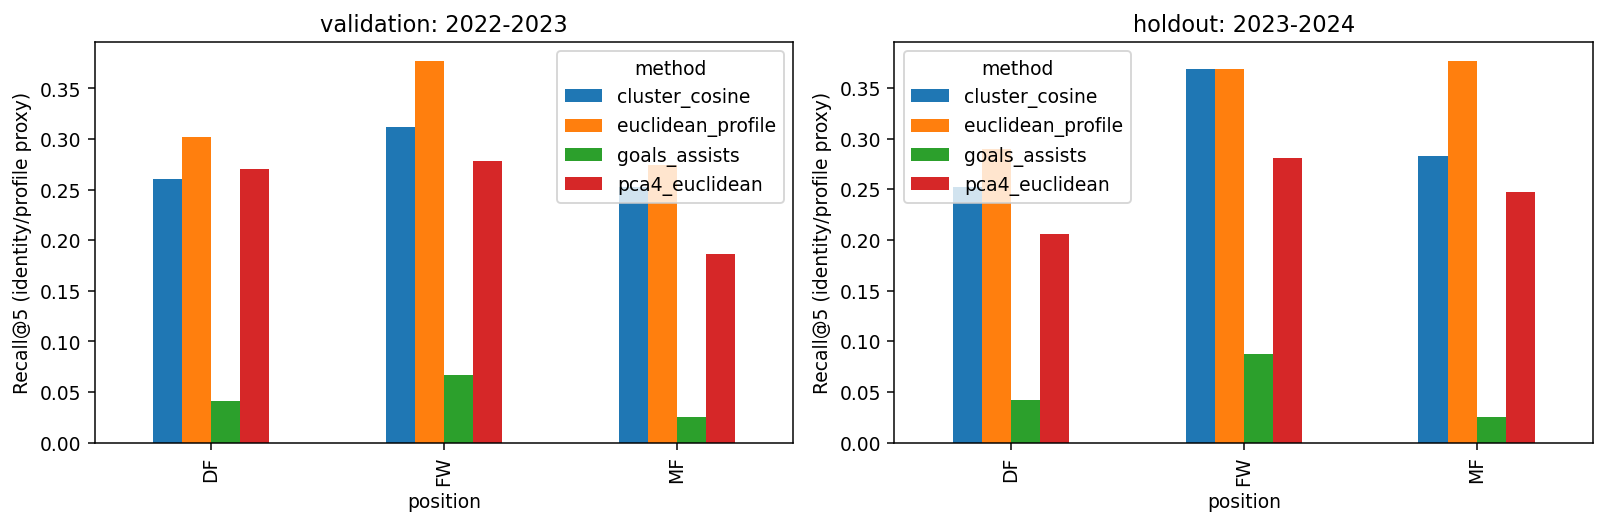

In [6]:
for name,info in result['experiments'].items():
    metrics=frame(name,'position_retrieval')
    selected=metrics[metrics.method.eq(info['selected_method'])]
    display(Markdown('### '+name))
    display(selected[['evaluation_season','position','queries','mrr','recall_at_5','mrr_delta_goals_assists','delta_ci_low','delta_ci_high']])
    # Independently reconcile subgroup means with the original complete holdout.
    hold=selected[selected.phase.eq('holdout')]
    assert int(hold.queries.sum())==base['experiments'][name]['holdout_queries']
    assert np.isclose(np.average(hold.mrr,weights=hold.queries),base['experiments'][name]['holdout_metrics']['mrr'])
    worst=hold.sort_values('mrr').iloc[0]
    display(Markdown(f"Lowest holdout identity/profile retrieval here: {worst.position}, MRR {worst.mrr:.3f} across {int(worst.queries)} queries. Position differences describe these archive cohorts and are not scouting accuracy estimates."))
figure('core','positions')


## Temporal drift and frozen-cluster transitions

Original development transformations and centres are frozen for every season. Feature drift uses observed rates only, reports missingness separately and uses training quantile histogram bins with infinite outer tails. Jensen–Shannon divergence (base 2) is bounded between 0 and 1; no arbitrary alert threshold or independence-based significance test is applied. Mean shifts use the original training standard deviation. Silhouette on frozen labels is descriptive; it does not reselect K. Transition matrices include only returning source identities and use their prior position, so their changes can reflect roles, exposure or roster selection rather than a causal tactical change.

### offensive

,phase,season,observations,silhouette,status
0,train,2020-2021,396,0.478125,measured
1,train,2021-2022,399,0.483626,measured
2,train,2022-2023,388,0.480992,measured
3,validation,2023-2024,393,0.491472,measured
4,holdout,2024-2025,399,0.462425,measured


,,returners,changed,changed_fraction
query_season,evaluation_season,,,
2020-2021,2021-2022,270,29,0.107407
2021-2022,2022-2023,248,31,0.125000
2022-2023,2023-2024,249,21,0.084337
2023-2024,2024-2025,243,26,0.106996


,phase,season,feature,observed_train,observed_future,missing_train,missing_future,histogram_bins,mean_train,mean_future,mean_shift_training_sd,js_divergence
9,holdout,2024-2025,sot_p90,1183,399,0,0,10,0.381402,0.391648,0.028008,0.008087
5,validation,2023-2024,xag_p90,1181,393,2,0,10,0.088863,0.094442,0.075128,0.007784
11,holdout,2024-2025,xag_p90,1181,399,2,0,10,0.088863,0.091487,0.035335,0.007334
7,holdout,2024-2025,ast_p90,1183,399,0,0,8,0.084394,0.085281,0.009083,0.005812
1,validation,2023-2024,ast_p90,1183,393,0,0,8,0.084394,0.091164,0.069320,0.005411
10,holdout,2024-2025,xg_p90,1181,399,2,0,10,0.129482,0.133517,0.028969,0.005218


Largest binned distribution difference: sot_p90 in 2024-2025, JS divergence 0.0081, mean change +0.028 training SD. Archive/category comparability and changed player exposure must be considered before attributing this to football evolution.

...

### attack_on_core

,phase,season,observations,silhouette,status
0,train,2020-2021,396,0.477888,measured
1,train,2021-2022,399,0.478498,measured
2,validation,2022-2023,388,0.480706,measured
3,holdout,2023-2024,393,0.491615,measured


,,returners,changed,changed_fraction
query_season,evaluation_season,,,
2020-2021,2021-2022,270,33,0.122222
2021-2022,2022-2023,248,33,0.133065
2022-2023,2023-2024,249,23,0.092369


,phase,season,feature,observed_train,observed_future,missing_train,missing_future,histogram_bins,mean_train,mean_future,mean_shift_training_sd,js_divergence
11,holdout,2023-2024,xag_p90,795,393,0,0,10,0.086299,0.094442,0.110281,0.011342
2,validation,2022-2023,sh_p90,795,388,0,0,10,1.131664,1.260545,0.151980,0.009042
5,validation,2022-2023,xag_p90,795,386,0,2,10,0.086299,0.094144,0.106250,0.008944
8,holdout,2023-2024,sh_p90,795,393,0,0,10,1.131664,1.223544,0.108348,0.007200
3,validation,2022-2023,sot_p90,795,388,0,0,10,0.367143,0.410619,0.122726,0.006538
9,holdout,2023-2024,sot_p90,795,393,0,0,10,0.367143,0.415849,0.137489,0.004738


Largest binned distribution difference: xag_p90 in 2023-2024, JS divergence 0.0113, mean change +0.110 training SD. Archive/category comparability and changed player exposure must be considered before attributing this to football evolution.

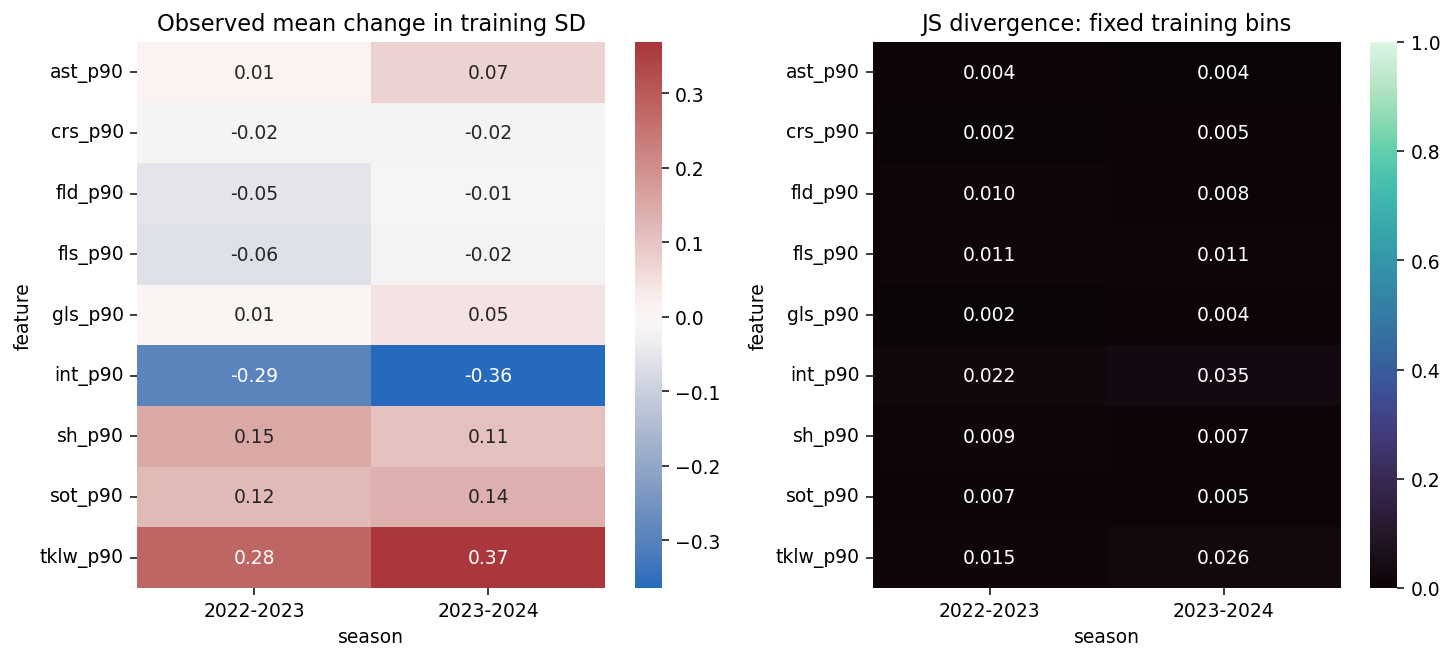

In [7]:
for name in result['experiments']:
    display(Markdown('### '+name))
    display(frame(name,'temporal_cluster_quality'))
    changes=frame(name,'cluster_transitions')
    changes['changed']=changes.cluster_previous.ne(changes.cluster_future)*changes.returning_players
    summary=changes.groupby(['query_season','evaluation_season']).agg(returners=('returning_players','sum'),changed=('changed','sum'))
    summary['changed_fraction']=summary.changed/summary.returners
    display(summary)
    drift=frame(name,'feature_drift').copy()
    display(drift.sort_values('js_divergence',ascending=False).head(6))
    maximum=drift.sort_values('js_divergence',ascending=False).iloc[0]
    display(Markdown(f"Largest binned distribution difference: {maximum.feature} in {maximum.season}, JS divergence {maximum.js_divergence:.4f}, mean change {maximum.mean_shift_training_sd:+.3f} training SD. Archive/category comparability and changed player exposure must be considered before attributing this to football evolution."))
figure('core','drift')


## All six original expert-defined playing styles

Possession, high pressing, vertical play, counterattack, defensive solidity and wing play remain separate scoring directions. They are not K-means clusters. The core model supports all six under the existing measured-weight rule (at least 60% absolute configured weight). Offensive tracks report limited support instead of assigning missing defensive features zero. Rankings below use a fixed last-development-season gallery and broad positions; they have no dated budget constraints. Resampling checks preprocessing sensitivity with fixed expert weights, not whether the weights represent real pressing, passing progression or transitions. Pairwise shortlist overlap can reveal redundant directions.

### offensive

,style,measured_weight_fraction,supported
0,posesion,0.50,False
1,presion_alta,0.15,False
2,vertical,0.70,True
3,contraataque,0.60,True
4,solidez_defensiva,0.15,False
5,desborde_banda,0.50,False


### core

,style,measured_weight_fraction,supported
0,posesion,0.85,True
1,presion_alta,0.85,True
2,vertical,0.85,True
3,contraataque,0.80,True
4,solidez_defensiva,0.95,True
5,desborde_banda,0.85,True


### attack_on_core

,style,measured_weight_fraction,supported
0,posesion,0.50,False
1,presion_alta,0.15,False
2,vertical,0.70,True
3,contraataque,0.60,True
4,solidez_defensiva,0.15,False
5,desborde_banda,0.50,False


mean       min  max
method            position                         
contraataque      DF        1.000000  1.000000  1.0
                  FW        1.000000  1.000000  1.0
                  MF        0.922222  0.666667  1.0
desborde_banda    DF        1.000000  1.000000  1.0
                  FW        0.833333  0.666667  1.0
                  MF        0.800000  0.666667  1.0
posesion          DF        0.900000  0.666667  1.0
                  FW        0.877778  0.666667  1.0
                  MF        0.877778  0.666667  1.0
presion_alta      DF        0.844444  0.666667  1.0
                  FW        0.955556  0.666667  1.0
                  MF        0.788889  0.666667  1.0
solidez_defensiva DF        1.000000  1.000000  1.0
                  FW        1.000000  1.000000  1.0
                  MF        0.988889  0.666667  1.0
vertical          DF        0.922222  0.666667  1.0
                  FW        0.701587  0.428571  1.0
                  MF        0.833333  0.666667  1.0

,style,position,rank,entity_id,player,season,team,measured_weight_fraction,affinity,interpretation
0,posesion,DF,1,fbref:63f04c6c,Alfonso Pedraza,2021-2022,Villarreal,0.85,0.757990,Expert-weighted descriptive style; no relevanc...
1,posesion,DF,2,fbref:5b28b2f6,Josan,2021-2022,Elche,0.85,0.696152,Expert-weighted descriptive style; no relevanc...
2,posesion,DF,3,fbref:b05e2dbd,José Luis Gayà,2021-2022,Valencia,0.85,0.588000,Expert-weighted descriptive style; no relevanc...
3,posesion,DF,4,fbref:ed9f7cfe,Renan Lodi,2021-2022,Atlético Madrid,0.85,0.574227,Expert-weighted descriptive style; no relevanc...
4,posesion,DF,5,fbref:603116a7,Marcelo,2021-2022,Real Madrid,0.85,0.539338,Expert-weighted descriptive style; no relevanc...
...,...,...,...,...,...,...,...,...,...,...
85,desborde_banda,FW,1,fbref:de39485a,Yannick Carrasco,2021-2022,Atlético Madrid,0.85,0.859966,Expert-weighted descriptive style; no relevanc...
86,desborde_banda,FW,2,fbref:b19db005,Ousmane Dembélé,2021-2022,Barcelona,0.85,0.793860,Expert-weighted descriptive style; no relevanc...
87,desborde_banda,FW,3,fbref:8c3c640c,Mikel Oyarzabal,2021-2022,Real Sociedad,0.85,0.788548,Expert-weighted descriptive style; no relevanc...
88,desborde_banda,FW,4,fbref:d8712bf9,Bebé,2021-2022,Rayo Vallecano,0.85,0.753093,Expert-weighted descriptive style; no relevanc...


,position,style_left,style_right,top5_jaccard
37,FW,presion_alta,solidez_defensiva,1.000000
4,DF,posesion,desborde_banda,0.666667
11,DF,vertical,desborde_banda,0.666667
9,DF,vertical,contraataque,0.666667
1,DF,posesion,vertical,0.666667
17,MF,posesion,contraataque,0.666667
22,MF,presion_alta,solidez_defensiva,0.666667
7,DF,presion_alta,solidez_defensiva,0.666667
2,DF,posesion,contraataque,0.428571
19,MF,posesion,desborde_banda,0.428571


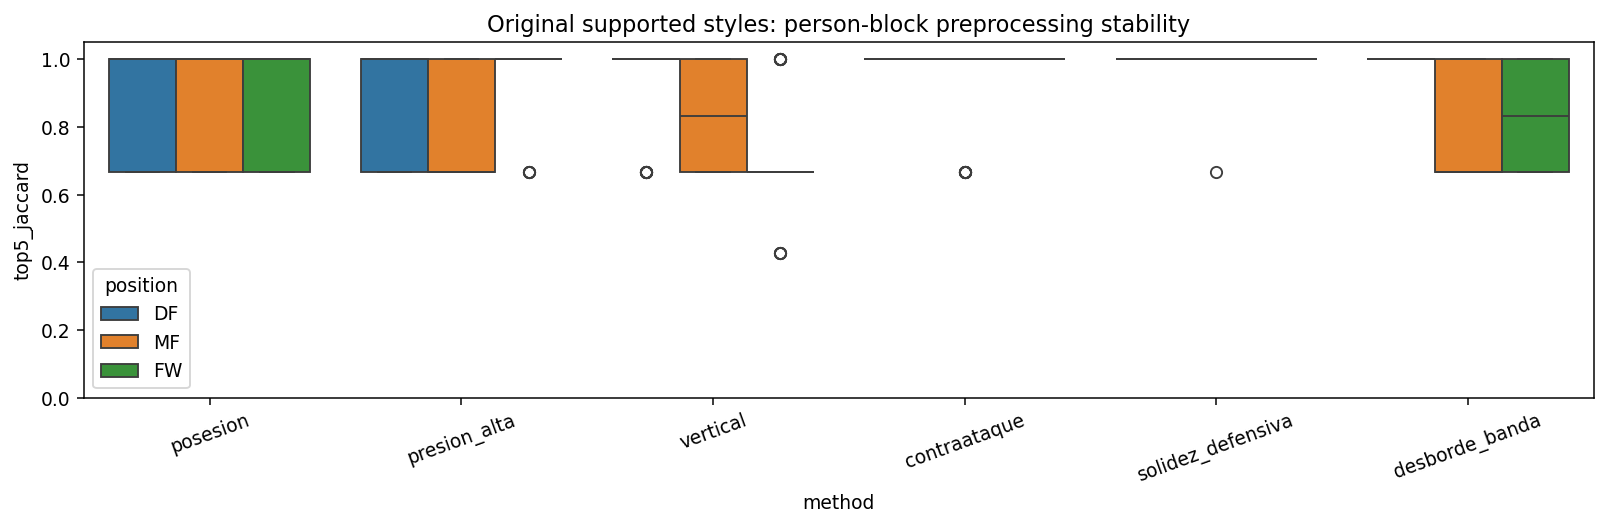

All six core style rankings were exercised on real historical players. High overlap or bootstrap stability alone does not validate the style names or establish club fit.

In [8]:
for name in result['experiments']:
    display(Markdown('### '+name)); display(frame(name,'style_coverage'))
core=frame('core','style_coverage'); assert len(core)==6 and core.supported.all()
stability=frame('core','ranking_bootstrap').query('kind == "style"')
display(stability.groupby(['method','position']).top5_jaccard.agg(['mean','min','max']))
display(frame('core','style_shortlists'))
display(frame('core','style_overlap').sort_values('top5_jaccard',ascending=False).head(10))
figure('core','styles')
display(Markdown('All six core style rankings were exercised on real historical players. High overlap or bootstrap stability alone does not validate the style names or establish club fit.'))


## MLflow lineage and remaining validation

Validation runs are separate from the original model-comparison runs and synthetic demonstrations. Each refers to its frozen model run and checksum, dataset/version, code hashes, Git commit and post-hoc design. Evaluation tables, plots and lineage are exported from finished logged artifacts using relative paths. Actual historical transfers, licensed dated budgets, independently reviewed identity labels and genuine scouting decisions are still required for external validation. No output here substitutes for those labels.

In [9]:
import mlflow
from mlflow.tracking import MlflowClient
mlflow.set_tracking_uri('sqlite:///mlflow.db')
client=MlflowClient()
for name,info in result['experiments'].items():
    record=json.loads((ROOT/f'reports/mlflow_export/collected_validation_{name}_run.json').read_text())
    logged=client.get_run(info['mlflow_run_id'])
    assert record['status']==logged.info.status=='FINISHED'
    assert logged.data.tags['base_model_run_id']==info['base_run_id']
    assert logged.data.tags['validation_version']==result['validation_version']
    display(pd.DataFrame([dict(cohort=name,run_id=logged.info.run_id,base_run_id=info['base_run_id'],status=logged.info.status)]))
display(Markdown('Remaining limits: '+ '; '.join(result['limitations'])))


,cohort,run_id,base_run_id,status
0,offensive,af3368bcb5394e6faf44a427ebec673a,c9e47c4ca7984652b79dd95131063041,FINISHED


,cohort,run_id,base_run_id,status
0,core,7b7e78d3d42e4753a61244aa65ac0de5,28aca2ec30514eafa181b7945f2c6dcd,FINISHED


,cohort,run_id,base_run_id,status
0,attack_on_core,050bbe2c72854f1dac316234895bd7a1,54262e95cd684023bed779bced078bb2,FINISHED


Remaining limits: Bootstrap distributions are conditional diagnostics, not external accuracy intervals; Previously viewed holdouts and subgroup analyses are post hoc, not new confirmation; Frozen-cluster transitions are descriptive and subject to returning-player selection; PCA directions use common standardized axes; eigenvector rotation is assessed via subspaces; Six original styles remain expert-defined proxies, without independently measured tactical relevance; Dated budgets, complete Segunda data, actual transfer validation and verified cross-source identities remain unavailable